## 2-1. RFM Segmentation
- Q. 고객의 구매 행동 차이를 어떻게 구분하고, 어떤 고객군을 우선 관리해야 하는가?
- Objective : Recency, Frequency, Monetary를 기반으로 고객을 세분화하고, 고객군별 행동 차이 확인

In [41]:
rfm_df = pd.read_sql("""
WITH ref AS (
    SELECT DATE_ADD(MAX(order_date), INTERVAL 1 DAY) AS ref_date
    FROM records
    )
SELECT customer_id
    , DATEDIFF(
        (SELECT ref_date FROM ref)
        , MAX(order_date)) recency
    , COUNT(DISTINCT order_id) AS frequency
    , ROUND(SUM(sales), 2) AS monetary
FROM records
GROUP BY customer_id
""", conn)

In [42]:
rfm_df

,customer_id,recency,frequency,monetary
0,AA-10315,185,1,374.48
1,AA-10375,20,2,206.73
2,AA-10480,260,1,15.55
3,AA-10645,56,1,12.96
4,AB-10060,55,4,2936.26
...,...,...,...,...
688,XP-21865,44,4,449.31
689,YC-21895,5,1,750.68
690,YS-21880,10,5,5340.26
691,ZC-21910,55,4,227.07


In [43]:
mean_val = rfm_df["recency"].mean()
median_val = rfm_df["recency"].median()
q1_val = rfm_df["recency"].quantile(0.25)
q3_val = rfm_df["recency"].quantile(0.75)

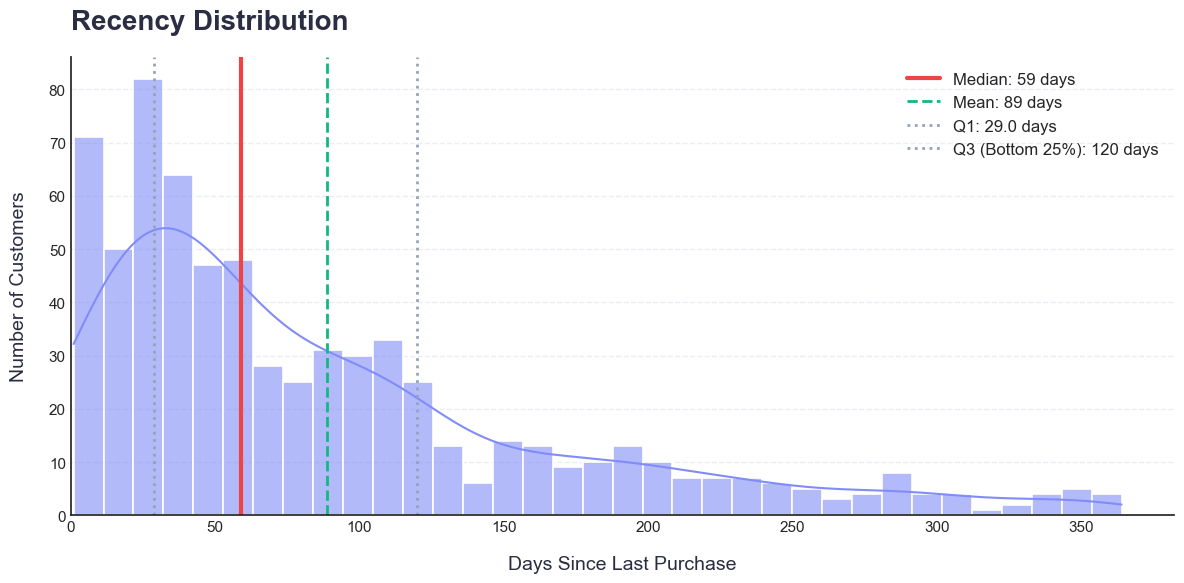

In [44]:
plt.style.use("seaborn-v0_8-white")
plt.figure(figsize=(12, 6))

sns.histplot(rfm_df["recency"], bins = 35, kde = True, color = "#818CF8", alpha = 0.6, edgecolor = "white", linewidth = 1.2)
# sns.kdeplot(rfm_df["recency"], color = "#2563EB", linewidth = 2.5)

plt.axvline(median_val, color = "#EF4444", linestyle = "-", linewidth = 3, label = f"Median: {median_val:.0f} days")
plt.axvline(mean_val, color = "#10B981", linestyle = "--", linewidth = 2, label = f'Mean: {mean_val:.0f} days')
plt.axvline(q1_val, color = "#94A3B8", linestyle = ":", linewidth = 2, label = f'Q1: {q1_val} days')
plt.axvline(q3_val, color = "#94A3B8", linestyle = ":", linewidth = 2, label=f'Q3 (Bottom 25%): {q3_val:.0f} days')

plt.title("Recency Distribution", fontsize = 20, fontweight = "bold", pad = 20, loc = "left", color = "#2B2D42")
plt.xlabel("Days Since Last Purchase", color = "#2B2D42", fontsize = 14, labelpad = 15)
plt.ylabel("Number of Customers", color = "#2B2D42", fontsize = 14, labelpad = 15)

# 배경영역 강조(이탈 위험 구간 표시)
#plt.axvspan(median_val, 400, color = "#F8F9FA", alpha = 0.5, label = "Inactivity Zone")

plt.xlim(left = 0)
plt.margins(x = 0.1)

sns.despine(top = True, right = True)
plt.grid(axis = "y", linestyle = "--", alpha = 0.4, color = "#CBD5E1")

plt.legend(frameon = False, fontsize = 12, loc = "upper right")

plt.tight_layout()
plt.show()

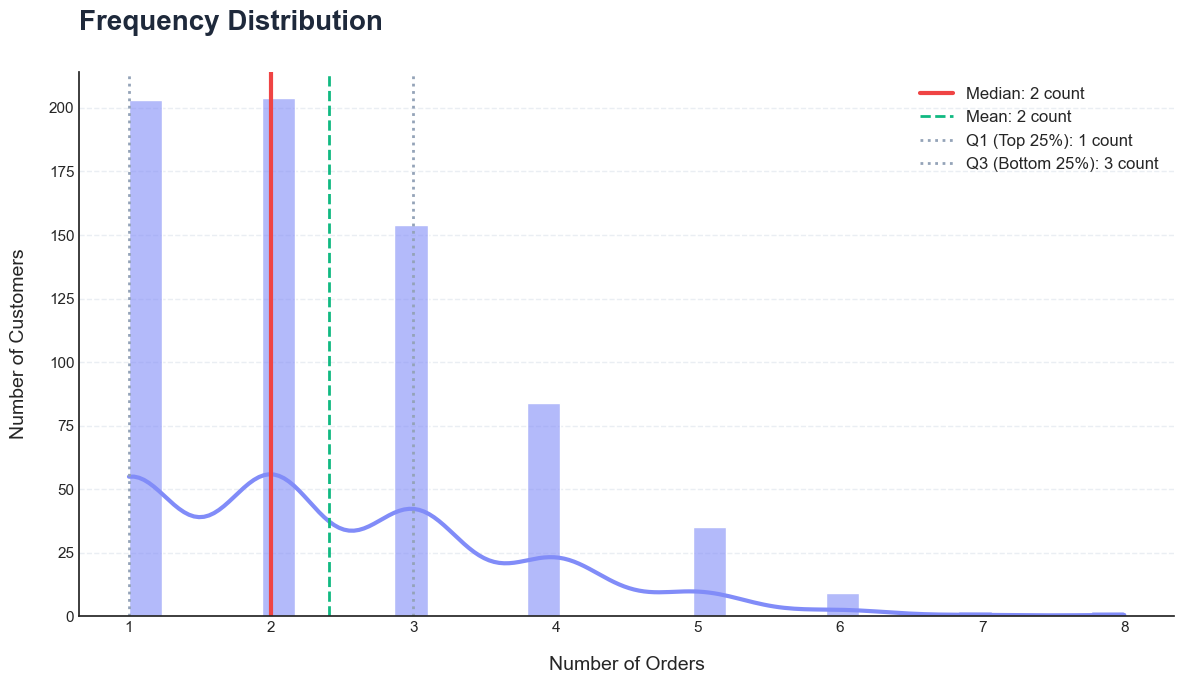

In [45]:
# frequency
mean_val = rfm_df["frequency"].mean()
median_val = rfm_df["frequency"].median()
q1_val = rfm_df["frequency"].quantile(0.25)
q3_val = rfm_df["frequency"].quantile(0.75)

plt.figure(figsize=(12, 7))

sns.histplot(rfm_df["frequency"], bins = 30, kde = True, color = "#818CF8", alpha = 0.6, edgecolor = "white"
             , line_kws = {"color": "#2563EB", "linewidth" : 3})

plt.axvline(median_val, color = "#EF4444", linestyle = "-", linewidth = 3, label = f'Median: {median_val:.0f} count')
plt.axvline(mean_val, color = "#10B981", linestyle = "--", linewidth = 2, label = f'Mean: {mean_val:.0f} count')
plt.axvline(q1_val, color = "#94A3B8", linestyle = ":", linewidth = 2, label = f'Q1 (Top 25%): {q1_val:.0f} count')
plt.axvline(q3_val, color = "#94A3B8", linestyle = ":", linewidth = 2, label=f'Q3 (Bottom 25%): {q3_val:.0f} count')

plt.title("Frequency Distribution", fontsize = 20, fontweight = "bold", pad = 30, loc = "left", color = "#1E293B")
plt.xlabel("Number of Orders", fontsize = 14, labelpad = 15)
plt.ylabel("Number of Customers", fontsize = 14, labelpad = 15)

# 배경영역 강조(이탈 위험 구간 표시)
#plt.axvspan(median_val, 400, color = "#F8F9FA", alpha = 0.5, label = "Inactivity Zone")

plt.legend(frameon = False, fontsize = 12, loc = "upper right")
sns.despine(top = True, right = True)
plt.grid(axis = "y", linestyle = "--", alpha = 0.4, color = "#CBD5E1")

plt.tight_layout()
plt.show()

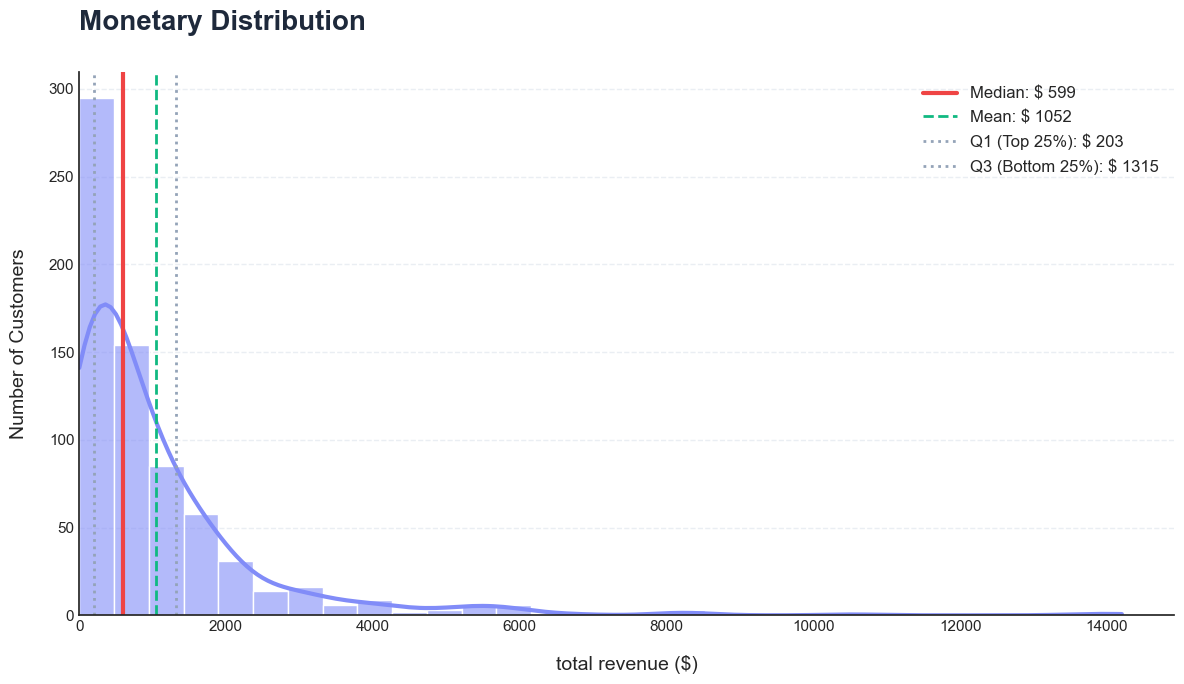

In [46]:
# monetary
mean_val = rfm_df["monetary"].mean()
median_val = rfm_df["monetary"].median()
q1_val = rfm_df["monetary"].quantile(0.25)
q3_val = rfm_df["monetary"].quantile(0.75)

plt.figure(figsize=(12, 7))

sns.histplot(rfm_df["monetary"], bins = 30, kde = True, color = "#818CF8", alpha = 0.6, edgecolor = "white"
             , line_kws = {"color": "#2563EB", "linewidth" : 3})

plt.axvline(median_val, color = "#EF4444", linestyle = "-", linewidth = 3, label = f'Median: $ {median_val:.0f}')
plt.axvline(mean_val, color = "#10B981", linestyle = "--", linewidth = 2, label = f'Mean: $ {mean_val:.0f}')
plt.axvline(q1_val, color = "#94A3B8", linestyle = ":", linewidth = 2, label = f'Q1 (Top 25%): $ {q1_val:.0f}')
plt.axvline(q3_val, color = "#94A3B8", linestyle = ":", linewidth = 2, label = f'Q3 (Bottom 25%): $ {q3_val:.0f}')

plt.title("Monetary Distribution", fontsize = 20, fontweight = "bold", pad = 30, loc = "left", color = "#1E293B")
plt.xlabel("total revenue ($)", fontsize = 14, labelpad = 15)
plt.ylabel("Number of Customers", fontsize = 14, labelpad = 15)

# 배경영역 강조(이탈 위험 구간 표시)
#plt.axvspan(median_val, 400, color = "#F8F9FA", alpha = 0.5, label = "Inactivity Zone")

plt.xlim(left = 0)
plt.margins(x = 0.1)

plt.legend(frameon = False, fontsize = 12, loc = "upper right")
sns.despine(top = True, right = True)
plt.grid(axis = "y", linestyle = "--", alpha = 0.4, color = "#CBD5E1")

plt.tight_layout()
plt.show()

In [47]:
### lorenz curve

# 1. 매출액 기준 내림차순 정렬
monetary_values = rfm_df["monetary"].sort_values(ascending = False).values
n_customers = len(monetary_values)

# 2. 누적 비율
# 고객 누적 비율(x축)
cum_customers = np.arange(1, n_customers + 1) / n_customers

# 매출 누적 비율(y축)
cum_revenue = np.cumsum(monetary_values) / np.sum(monetary_values)

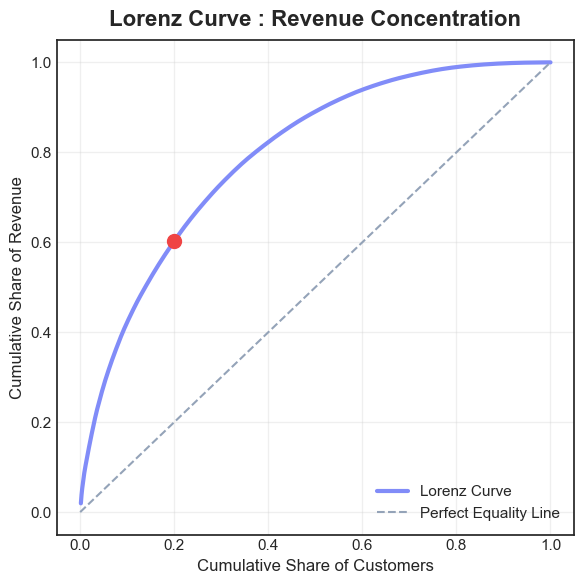

In [48]:
plt.figure(figsize = (6, 6))

plt.plot(cum_customers, cum_revenue, color = "#818CF8", linewidth = 3, label = "Lorenz Curve")
plt.plot([0, 1], [0, 1], color = "#94A3B8", linestyle = "--", label = "Perfect Equality Line")

# 파레토 포인트 표시(상위 20% 고객들의 매출 비중)
pareto_idx = np.argmin(np.abs(cum_customers - 0.2)) # 20%와 가장 자까운 고객 1명
pareto_rev = cum_revenue[pareto_idx]

plt.scatter(0.2, pareto_rev, color = "#EF4444", s = 100, zorder = 5)
#plt.annotate(f"Top 20% Customers/n contribute {pareto_rev:.1f} of Revenue"
#             , xy = (0.2, pareto_rev)
#             , xytext = (0.4, 0.4)
#             , arrowprops = dict(facecolor = "black", shrink = 0.05)
#             , fontsize = 12
#             , fontweight = "bold"
#            )

plt.title("Lorenz Curve : Revenue Concentration", fontsize = 16, fontweight = "bold", pad = 10)
plt.xlabel("Cumulative Share of Customers", fontsize = 12)
plt.ylabel("Cumulative Share of Revenue", fontsize = 12)
plt.legend(loc = "lower right")
plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

In [49]:
pareto_rev

np.float64(0.6034554565952522)

## 2-2. 세그먼트별 점수화

In [53]:
segment_df = pd.read_sql("""SELECT * FROm rfm_segment_new3""", conn)
segment_df

,customer_id,recency,frequency,monetary,r_score,f_score,m_score,segment
0,PC-18745,4,1,1.188,5,2,1,New Customers
1,TS-21085,360,1,2.808,1,1,1,Hibernating
2,TB-21595,287,1,2.910,1,1,1,Hibernating
3,JM-15580,2,1,3.024,5,2,1,New Customers
4,TZ-21580,37,1,5.160,4,2,1,New Customers
...,...,...,...,...,...,...,...,...
688,GT-14635,58,1,8167.420,3,2,5,Need Attention
689,SV-20365,103,4,8365.185,2,5,5,Lost VIP
690,HL-15040,45,2,10522.550,3,3,5,Potential Loyal
691,TA-21385,71,2,13723.498,3,3,5,Potential Loyal


In [54]:
# 세그먼트별 매출 기여도
group_df = pd.read_sql("""SELECT
    s.segment AS rfm_segment,
    COUNT(DISTINCT s.customer_id) AS customer_cnt,
    COUNT(DISTINCT r.order_id) AS order_cnt, # frequency
    ROUND(SUM(r.sales), 2) AS revenue, # monetary
    ROUND(SUM(r.sales) / COUNT(DISTINCT s.customer_id), 2) AS arppu, # 구매 고객 1명당 평균 매출
    ROUND(SUM(r.sales) / COUNT(DISTINCT r.order_id), 2) AS aov, # 주문 1건당 평균 구매 금액
    ROUND(SUM(r.sales) * 100 / (SELECT SUM(sales) FROM records), 2) AS revenue_rate
FROM rfm_segment_new3 s
JOIN records r
    ON s.customer_id = r.customer_id
GROUP BY s.segment
ORDER BY revenue DESC""", conn)

group_df

,rfm_segment,customer_cnt,order_cnt,revenue,arppu,aov,revenue_rate
0,Potential Loyal,154,439,220502.95,1431.84,502.28,30.25
1,VIP,98,398,204094.81,2082.60,512.80,28.00
2,Lost VIP,29,111,101246.09,3491.24,912.13,13.89
3,Lost customers,160,321,81770.74,511.07,254.74,11.22
4,Need Attention,33,48,54739.36,1658.77,1140.40,7.51
5,Hibernating,151,283,40308.14,266.94,142.43,5.53
6,New Customers,41,41,20532.49,500.79,500.79,2.82
7,About to sleep,27,27,5839.59,216.28,216.28,0.80


In [56]:
group_df = group_df.sort_values("revenue", ascending = False)

In [57]:
segment_color_map = {
    # 핵심 매출 그룹 (Purple)
    "VIP": "#312E81",
    "Potential Loyal": "#4F46E5",

    # 성장 가능 그룹 (Blue)
    "New Customers": "#C7D2FE",
    #"Promising": "#93C5FD",

    # 관리 필요 (Green)
    "Need Attention": "#A5B4FC",

    # 고객 규모가 큰 휴면/이탈 그룹 (Slate Blue)
    "Hibernating": "#94A3B8",
    "Lost customers": "#64748B",

    # 이탈 직전
    "About to sleep": "#E2E8F0",

    # 위험
    "Lost VIP": "#E11D48",
}

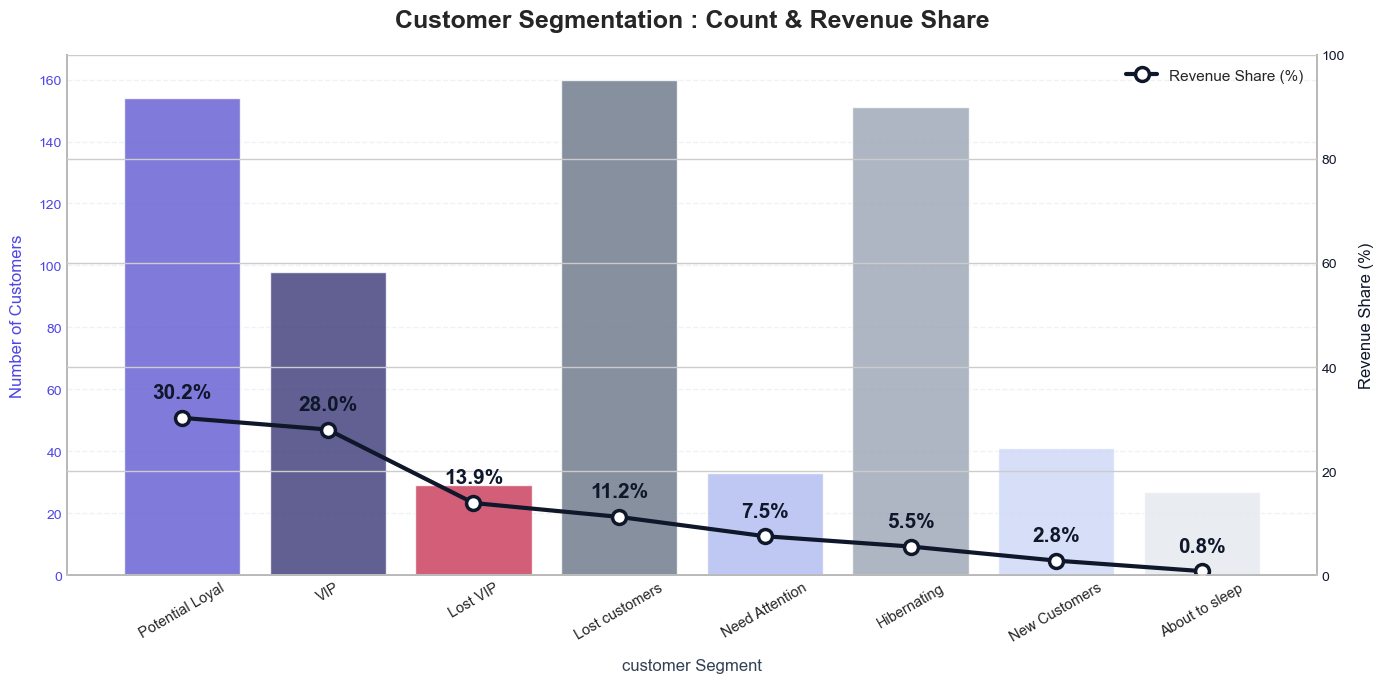

In [58]:
fig, ax1 = plt.subplots(figsize = (14, 7))
sns.set_style("whitegrid")

# 막대그래프 : 고객 수
bar_colors = [
    segment_color_map.get(seg, "#94A3B8") for seg in group_df["rfm_segment"]
]
sns.barplot(data = group_df, x = "rfm_segment", y = "customer_cnt", palette = bar_colors, ax = ax1, alpha = 0.8)

ax1.set_title("Customer Segmentation : Count & Revenue Share", fontsize = 18, fontweight = "bold", pad =  20)
ax1.set_xlabel("customer Segment", fontsize=12, labelpad=10, color="#334155")
ax1.set_ylabel("Number of Customers", fontsize=12, labelpad=10, color="#4F46E5")
ax1.tick_params(axis="y", labelcolor="#4F46E5", labelsize=10)
ax1.tick_params(axis="x", rotation=30, labelsize=10.5)

# 선그래프 : 매출 비중
ax2 = ax1.twinx()
sns.lineplot(data = group_df, x = "rfm_segment", y = "revenue_rate", marker = "o", color = "#0F172A"
             , linewidth = 3, markersize = 10, markerfacecolor = "#FFFFFF", markeredgewidth = 2.5, markeredgecolor = "#0F172A"
             , ax = ax2, label = "Revenue Share (%)")
ax2.set_ylabel("Revenue Share (%)", fontsize=12, labelpad=10, color="#0F172A")
ax2.tick_params(axis = "y", labelcolor = "#0F172A", labelsize=10)
ax2.set_ylim(0, 100) # 퍼센특 기준 고정

for i, v in enumerate(group_df["revenue_rate"]):
    ax2.text(i, v + 3, f"{v:.1f}%", color = "#0F172A", ha = "center", va = "bottom", fontweight = "bold", fontsize = 15)

ax1.grid(axis="y", linestyle="--", alpha=0.3, color="#CBD5E1")
sns.despine(top=True, right=False)

plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

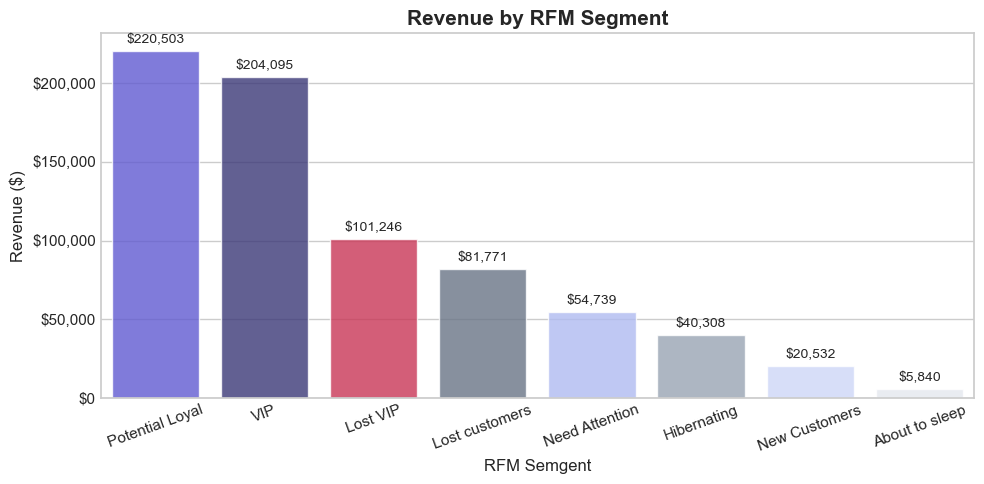

In [59]:
plt.figure(figsize = (10, 5))
ax = sns.barplot(data = group_df, x = "rfm_segment", y = "revenue", palette = bar_colors, alpha = 0.8)

for i, row in group_df.reset_index(drop = True).iterrows():
    ax.text(i, row["revenue"] + 5000, f"${row["revenue"]:,.0f}", ha = 'center', fontsize = 10)

plt.title("Revenue by RFM Segment", fontsize = 15, weight = "bold")
plt.xlabel("RFM Semgent")
plt.ylabel("Revenue ($)")
plt.gca().yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
plt.xticks(rotation = 20)
plt.tight_layout()
plt.show()

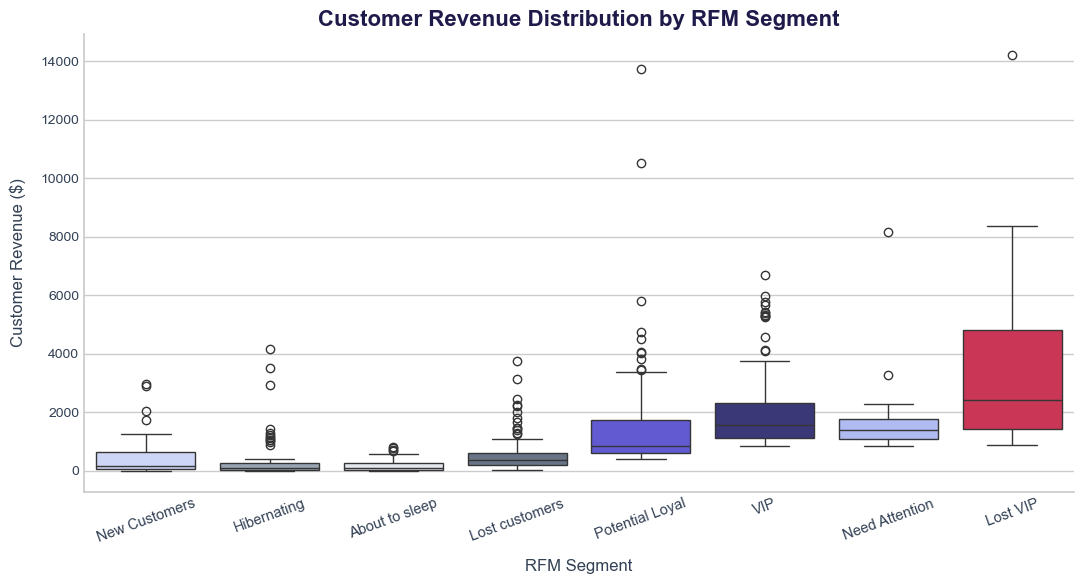

In [60]:
plt.figure(figsize=(11, 6))
sns.boxplot(
    data = segment_df,
    x = "segment",
    y = "monetary",
    palette = segment_color_map
)

plt.title("Customer Revenue Distribution by RFM Segment", fontsize=16, weight="bold", color = "#1E1B4B")

plt.xlabel("RFM Segment", fontsize=12, labelpad=10, color="#334155")
plt.ylabel("Customer Revenue ($)", fontsize=12, labelpad=10, color="#334155")

plt.xticks(rotation=20, fontsize=10.5, color="#334155")
plt.yticks(fontsize=10, color="#334155")

ax.grid(axis="y", linestyle="--", alpha=0.3, color="#CBD5E1")
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

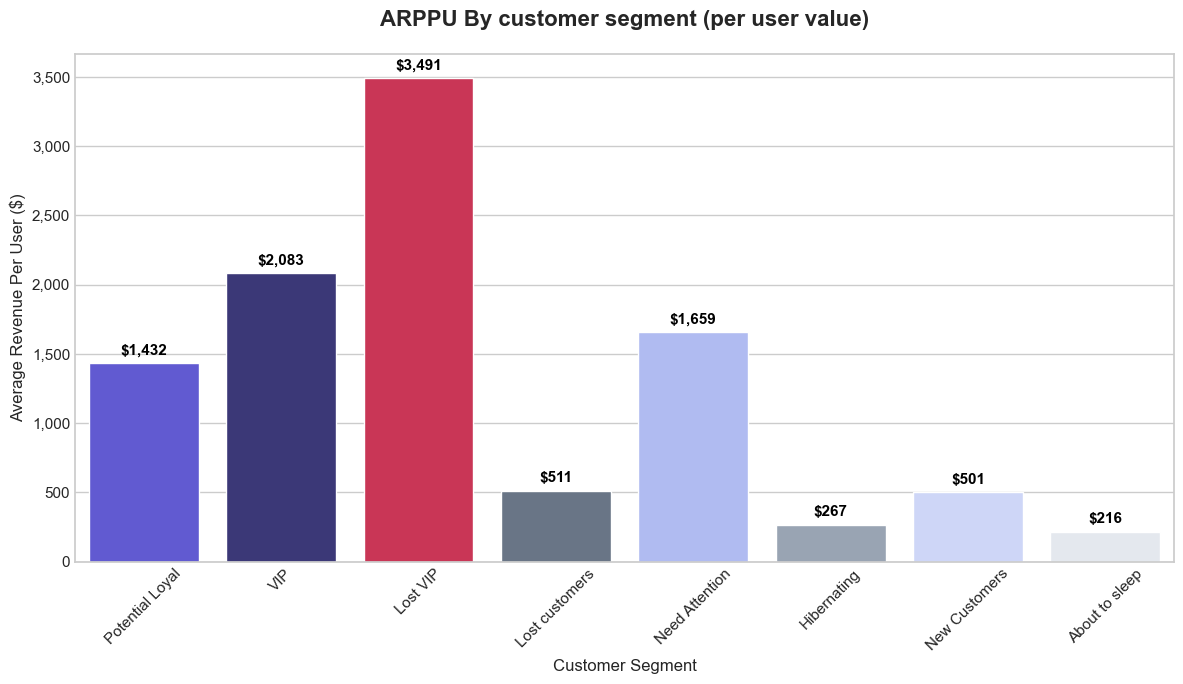

In [61]:
plt.figure(figsize = (12, 7))
sns.set_style("whitegrid")

bar = sns.barplot(data = group_df, x = "rfm_segment", y = "arppu", palette = bar_colors)

for p in bar.patches:
    bar.annotate(f"${p.get_height():,.0f}"
                 , (p.get_x() + p.get_width() / 2., p.get_height())
                 , ha = "center", va = "center"
                 , xytext = (0, 9)
                 , textcoords = "offset points"
                 , fontsize = 11
                 , fontweight = "bold"
                 , color = "#000000"
                )

plt.title("ARPPU By customer segment (per user value)", fontsize = 16, fontweight = "bold", pad = 20)
plt.xlabel("Customer Segment", fontsize = 12)
plt.ylabel("Average Revenue Per User ($)", fontsize = 12)
plt.xticks(rotation = 45)

plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))

plt.tight_layout()
plt.show()

In [62]:
segment_summary = (
    segment_df
    .groupby("segment")
    .agg({
        'frequency':'mean',
        'monetary':'mean',
        'customer_id':'count'
    })
    .reset_index()
)

segment_summary.columns = ["Segment", "Avg_Frequency", "ARPPU", "PU"]
segment_summary

,Segment,Avg_Frequency,ARPPU,PU
0,About to sleep,1.000000,216.281074,27
1,Hibernating,1.874172,266.941318,151
2,Lost VIP,3.827586,3491.244372,29
3,Lost customers,2.006250,511.067152,160
4,Need Attention,1.454545,1658.768376,33
5,New Customers,1.000000,500.792361,41
6,Potential Loyal,2.850649,1431.837308,154
7,VIP,4.061224,2082.600105,98


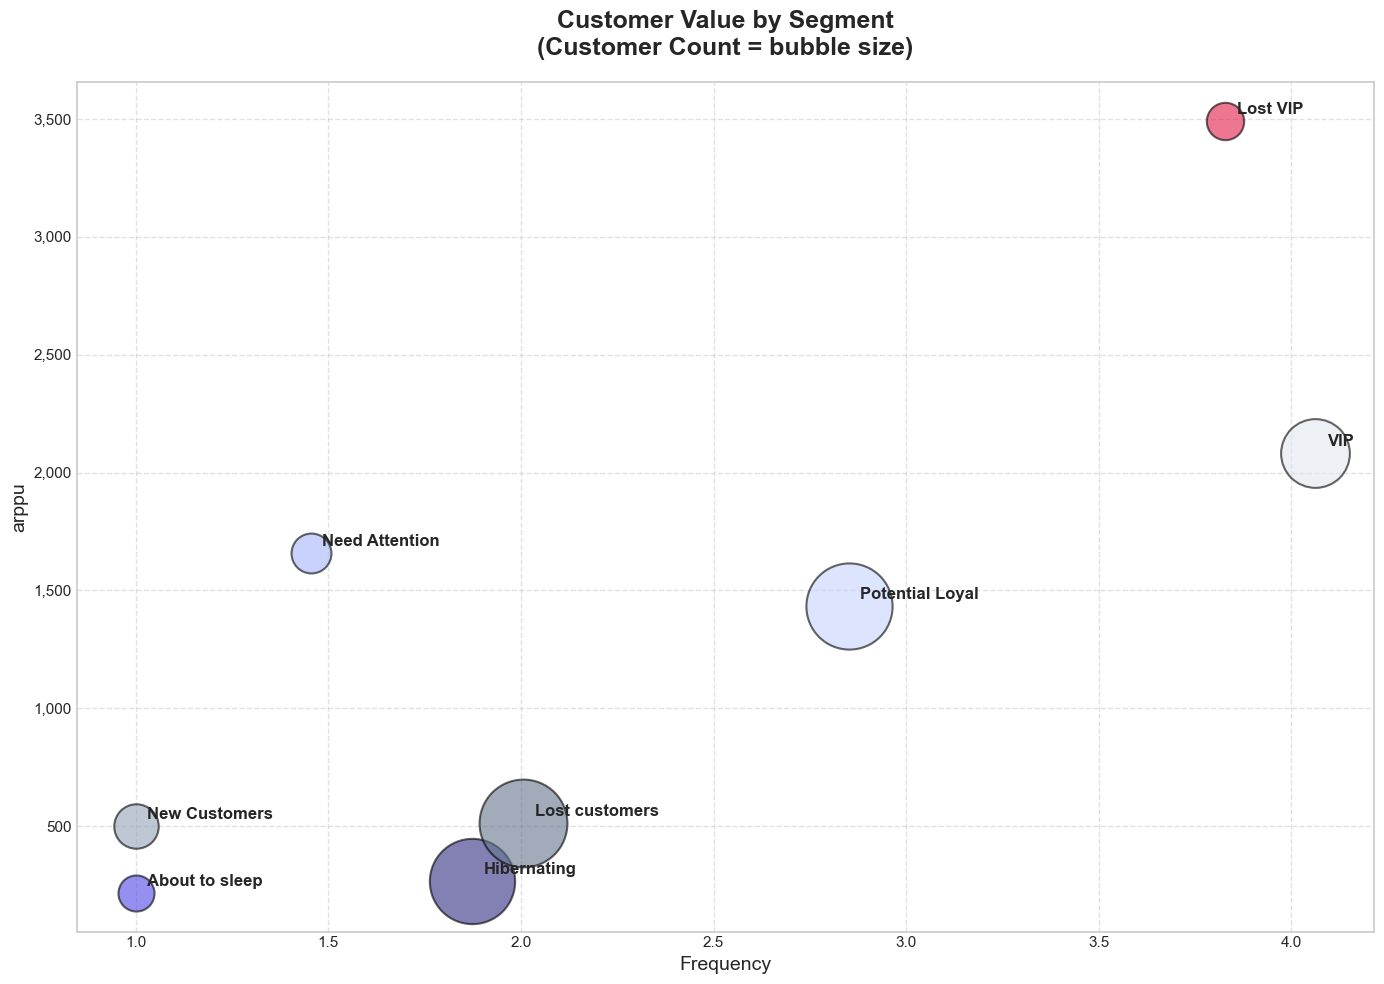

In [63]:
# RFM Segment map

plt.figure(figsize = (14, 10))
sns.set_style("whitegrid")

for i in range(len(segment_summary)):
    plt.scatter(x = segment_summary["Avg_Frequency"][i]
                , y = segment_summary["ARPPU"][i]
                , s = segment_summary["PU"][i] * 25
                , color = bar_colors[i]
                , alpha = 0.6
                , edgecolors = "black"
                , linewidth = 1.5
               )

texts = []
for i in range(len(segment_summary)):
    texts.append(plt.text(x = segment_summary.loc[i, "Avg_Frequency"] + 0.03
                         , y = segment_summary.loc[i, "ARPPU"] + 30
                         , s = segment_summary.loc[i, "Segment"]
                         , fontsize = 12
                         , fontweight = "bold"
                        )
                )

plt.title("Customer Value by Segment\n(Customer Count = bubble size)", fontsize = 18, fontweight = "bold", pad = 20)
plt.xlabel("Frequency", fontsize = 14)
plt.ylabel("arppu", fontsize = 14)

plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))

plt.grid(True, linestyle = "--", alpha = 0.6)
plt.tight_layout()
plt.show()

In [64]:
retained_summary = pd.read_sql("""
WITH first_purchase AS (
    SELECT
        customer_id,
        MIN(order_date) AS first_order
    FROM records
    GROUP BY customer_id
),

retained_customer AS (
    SELECT DISTINCT
        r.customer_id
    FROM records r
    JOIN first_purchase f
      ON r.customer_id = f.customer_id
    WHERE TIMESTAMPDIFF(
        MONTH,
        f.first_order,
        r.order_date
    ) >= 3
)

SELECT
    COUNT(DISTINCT customer_id) AS customer_cnt,
    ROUND(AVG(frequency),2) AS avg_frequency,
    ROUND(AVG(monetary),2) AS avg_arppu,
    ROUND(AVG(recency),2) AS avg_recency
FROM rfm_segment_new3
WHERE customer_id IN (
    SELECT customer_id
    FROM retained_customer
);
""", conn)

In [65]:
retained_summary

,customer_cnt,avg_frequency,avg_arppu,avg_recency
0,373,3.21,1376.61,60.47


In [66]:
overall_summary = pd.read_sql("""
SELECT
    COUNT(DISTINCT customer_id) AS customer_cnt,
    ROUND(AVG(frequency),2) AS avg_frequency,
    ROUND(AVG(monetary),2) AS avg_arppu,
    ROUND(AVG(recency),2) AS avg_recency
FROM rfm_segment_new3;
""", conn)

In [67]:
overall_summary

,customer_cnt,avg_frequency,avg_arppu,avg_recency
0,693,2.41,1052.0,89.69


In [68]:
comparison = pd.concat(
    [
        overall_summary.assign(group="All Customers"),
        retained_summary.assign(group="Retained Customers")
    ]
)

comparison = comparison[
    [
        "group",
        "customer_cnt",
        "avg_frequency",
        "avg_arppu",
        "avg_recency"
    ]
]

comparison

,group,customer_cnt,avg_frequency,avg_arppu,avg_recency
0,All Customers,693,2.41,1052.00,89.69
0,Retained Customers,373,3.21,1376.61,60.47


### 2-3. [추가분석] potential loyal은 vip가 되기 위해 어떤 행동변화가 필요한가?

In [69]:
target = segment_df[
    segment_df["segment"].isin(["Potential Loyal", "VIP"])
]

metrics = ["frequency", "monetary", "recency"]

In [70]:
# 평균 비교
rfm_compare_df = (
    target
    .groupby("segment")[metrics]
    .mean()
    .rename(columns={
        "frequency": "Avg_Frequency",
        "monetary": "Avg_Monetary",
        "recency": "Avg_Recency"
    })
    .round(2)
)

rfm_compare_df.loc["Gap"] = (rfm_compare_df.loc["VIP"] - rfm_compare_df.loc["Potential Loyal"])
rfm_compare_df = rfm_compare_df.round(2)

display(rfm_compare_df)

,Avg_Frequency,Avg_Monetary,Avg_Recency
segment,,,
Potential Loyal,2.85,1431.84,41.29
VIP,4.06,2082.60,22.66
Gap,1.21,650.76,-18.63


In [71]:
# vip 대비 달성률
achievement = pd.DataFrame({
    "Potential Loyal": rfm_compare_df.loc["Potential Loyal"],
    "VIP": rfm_compare_df.loc["VIP"]
})

achievement["Gap"] = np.where(
    achievement.index == "Recency",
    achievement["Potential Loyal"] - achievement["VIP"],
    achievement["VIP"] - achievement["Potential Loyal"]
).round(2)

achievement["VIP Benchmark (%)"] = (
    achievement["Potential Loyal"]
    / achievement["VIP"]
    * 100
).round(1)

display(achievement)

,Potential Loyal,VIP,Gap,VIP Benchmark (%)
Avg_Frequency,2.85,4.06,1.21,70.2
Avg_Monetary,1431.84,2082.60,650.76,68.8
Avg_Recency,41.29,22.66,-18.63,182.2


In [72]:
potential = target[target["segment"] == "Potential Loyal"]
vip = target[target["segment"] == "VIP"]

test_result  = []

for metric in metrics:

    u, p = mannwhitneyu(
        potential[metric],
        vip[metric],
        alternative='two-sided'
    )

    n1 = len(potential)
    n2 = len(vip)

    mean_u = n1 * n2 / 2
    std_u = np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12)

    z = (u - mean_u) / std_u
    r = abs(z) / np.sqrt(n1 + n2)

    test_result.append({
        "Metric": metric.capitalize(),
        "U Statistic": round(u, 2),
        "P-value": round(p, 6),
        "Effect Size (r)": round(r, 3)
    })

In [73]:
test_result = pd.DataFrame(test_result)

display(test_result)

,Metric,U Statistic,P-value,Effect Size (r)
0,Frequency,3079.0,0.0,0.499
1,Monetary,4122.0,0.0,0.382
2,Recency,11303.0,0.0,0.420


In [74]:
# 카테고리 차이
records_df['customer_id'] = records_df['customer_id'].astype(str)
segment_df['customer_id'] = segment_df['customer_id'].astype(str)

customer_segment_transactions = (
    records_df
        .merge(
            segment_df[['customer_id','segment']],
            on='customer_id',
            how = "left"
        )
        .rename(columns = {
            "segment_x" : "orin_segment"
            , "segment_y" : "rfm_segment"
        })
)
customer_segment_transactions

,order_id,order_date,ship_mode,customer_id,orin_segment,city,state,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit,rfm_segment
0,CA-2017-107503,2020-01-01,Standard Class,GA-14725,Consumer,Lorain,Ohio,44052,East,FUR-FU-10003878,Furniture,Furnishings,"Linden 10 Round Wall Clock, Black",48.896,4,0.2,8.5568,Potential Loyal
1,CA-2017-144463,2020-01-01,Standard Class,SC-20725,Consumer,Los Angeles,California,90036,West,FUR-FU-10001215,Furniture,Furnishings,Howard Miller 11-1/2 Diameter Brentwood Wall C...,474.430,11,0.0,199.2606,Lost customers
2,CA-2017-154466,2020-01-01,First Class,DP-13390,Home Office,Franklin,Wisconsin,53132,Central,OFF-BI-10002012,Office Supplies,Binders,Wilson Jones Easy Flow II Sheet Lifters,3.600,2,0.0,1.7280,Lost customers
3,CA-2017-151750,2020-01-01,Standard Class,JM-15250,Consumer,Huntsville,Texas,77340,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,454.560,5,0.2,-107.9580,VIP
4,CA-2017-151750,2020-01-01,Standard Class,JM-15250,Consumer,Huntsville,Texas,77340,Central,FUR-FU-10002116,Furniture,Furnishings,"Tenex Carpeted, Granite-Look or Clear Contempo...",141.420,5,0.6,-187.3815,VIP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3270,CA-2017-143259,2020-12-30,Standard Class,PO-18865,Consumer,New York City,New York,10009,East,TEC-PH-10004774,Technology,Phones,Gear Head AU3700S Headset,90.930,7,0.0,2.7279,VIP
3271,CA-2017-143259,2020-12-30,Standard Class,PO-18865,Consumer,New York City,New York,10009,East,OFF-BI-10003684,Office Supplies,Binders,Wilson Jones Legal Size Ring Binders,52.776,3,0.2,19.7910,VIP
3272,CA-2017-115427,2020-12-30,Standard Class,EB-13975,Corporate,Fairfield,California,94533,West,OFF-BI-10002103,Office Supplies,Binders,"Cardinal Slant-D Ring Binder, Heavy Gauge Vinyl",13.904,2,0.2,4.5188,New Customers
3273,CA-2017-115427,2020-12-30,Standard Class,EB-13975,Corporate,Fairfield,California,94533,West,OFF-BI-10004632,Office Supplies,Binders,GBC Binding covers,20.720,2,0.2,6.4750,New Customers


In [75]:
customer_segment_transactions = customer_segment_transactions[
    customer_segment_transactions['rfm_segment'].isin(['Potential Loyal','VIP'])
]

category_compare = (
    pd.crosstab(
        customer_segment_transactions['rfm_segment'],
        customer_segment_transactions['category'],
        normalize='index'
    )*100
).round(1)

category_compare

category,Furniture,Office Supplies,Technology
rfm_segment,,,
Potential Loyal,20.8,61.1,18.1
VIP,24.5,53.9,21.6


In [76]:
sub_compare = (
    pd.crosstab(
        customer_segment_transactions["rfm_segment"]
        , customer_segment_transactions["sub_category"]
        , normalize = "index"
    ) * 100
).round(1)
sub_compare

sub_category,Accessories,Appliances,Art,Binders,Bookcases,Chairs,Copiers,Envelopes,Fasteners,Furnishings,Labels,Machines,Paper,Phones,Storage,Supplies,Tables
rfm_segment,,,,,,,,,,,,,,,,,
Potential Loyal,7.2,5.1,7.0,16.5,2.4,6.1,0.8,2.3,1.9,9.2,4.1,0.4,14.0,9.6,8.2,2.1,3.1
VIP,10.3,4.7,7.7,13.4,2.2,6.9,0.7,1.6,1.8,11.7,2.2,1.5,12.8,9.1,8.1,1.6,3.8
